# 02. Reservoir Physics & Decision Agent Setup

- **Step 2 of 4:** Configure `case.json` (storage bounds, release limits, routing UHs) and compare Rule-based vs. LLM agents (`rule_based.yaml`, `seasonal_target.yaml`, `dkp.yaml`).
- **Pass Criterion:** `load_settings` validates all files offline with SHA-256 pinning and zero API calls.

In [1]:
import json
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

for p in (Path.cwd(), *Path.cwd().parents):
    if (p / "tutorials" / "_helpers.py").is_file():
        sys.path.insert(0, str(p))
        break
from tutorials import _helpers as h
from llm_reservoir_agent.workflow import load_settings

REPO_ROOT = h.find_repo_root()
C = h.configure_plots()

## 1. Inspect Reservoir Physics & Routing Weights (`case.json`)

Plot F.E. Walter's storage–elevation curve (conservation `1,300 ft`, recreation `1,370 ft`, spillway `1,450 ft`) and Lohmann downstream UH weights.

Capacity: 135.53 Mm3 | Dead: 49.3 m3 | Bounds: [1.42, 283.17] m3/s


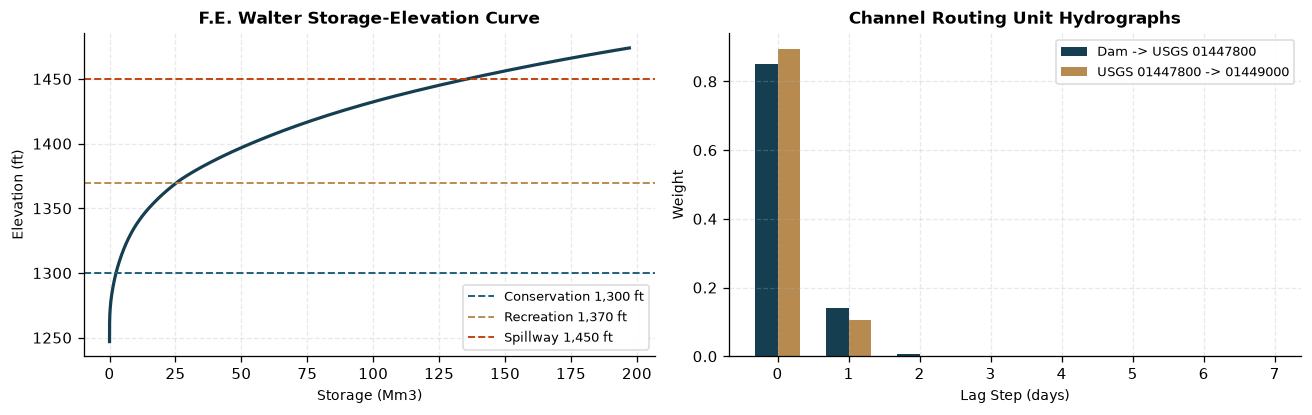

In [2]:
fe = REPO_ROOT / "examples" / "fe_walter"
case = json.loads((fe / "case.json").read_text(encoding="utf-8"))
phys = case["network"]["reservoirs"]["FEWalter"]["physical"]
print(f"Capacity: {phys['capacity_m3']/1e6:.2f} Mm3 | Dead: {phys['dead_storage_m3']:.1f} m3 | Bounds: [{phys['minimum_release_cms']:.2f}, {phys['maximum_release_cms']:.2f}] m3/s")

elev_ft, storage_m3, _ = h.load_fe_walter_curve(REPO_ROOT)
uh_dam_wh = case["network"]["connections"][0]["unit_hydrograph"][:8]
uh_wh_leh = case["network"]["connections"][1]["unit_hydrograph"]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.7))
axes[0].plot(storage_m3 / 1e6, elev_ft, color=C["navy"], lw=2.0)
for lvl, col, lbl in [(1300, C["teal"], "Conservation 1,300 ft"), (1370, C["gold"], "Recreation 1,370 ft"), (1450, C["coral"], "Spillway 1,450 ft")]:
    axes[0].axhline(lvl, color=col, ls="--", lw=1.2, label=lbl)
axes[0].set_title("F.E. Walter Storage-Elevation Curve"); axes[0].set_xlabel("Storage (Mm3)"); axes[0].set_ylabel("Elevation (ft)"); axes[0].legend(fontsize=8)

lags = np.arange(len(uh_dam_wh))
axes[1].bar(lags - 0.16, uh_dam_wh, 0.32, color=C["navy"], label="Dam -> USGS 01447800")
axes[1].bar(np.arange(len(uh_wh_leh)) + 0.16, uh_wh_leh, 0.32, color=C["gold"], label="USGS 01447800 -> 01449000")
axes[1].set_title("Channel Routing Unit Hydrographs"); axes[1].set_xlabel("Lag Step (days)"); axes[1].set_ylabel("Weight"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 2. Offline Preflight (`check`): Rule vs. LLM Agents

`load_settings` pins every prompt, statistic JSON, and `dkp.md` by SHA-256 and renders Day-1 prompts offline before spending API budget.

In [3]:
cfgs = {"Rule-based": "rule_based.yaml", "LLM (Seasonal Target)": "seasonal_target.yaml", "LLM + Knowledge (DKP)": "dkp.yaml"}
rows = []
reports = {}
for label, fname in cfgs.items():
    plan = load_settings(fe / fname, runtime_root=REPO_ROOT)
    reports[label] = plan.report
    rows.append({
        "Config": fname,
        "Agent Type": list(plan.report["agent_types"].values())[0],
        "Rule / Model": list(plan.report["agent_rules"].values())[0] if plan.report["agent_rules"] else "gemma4:12b (seed=3)",
        "Planned LLM Calls": plan.report["planned_llm_calls"],
        "Network Calls": plan.report["network_calls"],
        "Pinned Files": len(plan.files),
    })
print(pd.DataFrame(rows).to_string(index=False))

dkp_msg = reports["LLM + Knowledge (DKP)"]["prompt_previews"]["walter_operator"]["messages"][-1]["content"]
print("\nDay-1 DKP User Prompt Preview (truncated):")
print("\n".join(dkp_msg.splitlines()[:8]))

              Config Agent Type        Rule / Model  Planned LLM Calls  Network Calls  Pinned Files
     rule_based.yaml rule_based            hanasaki                  0              0             6
seasonal_target.yaml        llm gemma4:12b (seed=3)                  7              0            13
            dkp.yaml        llm gemma4:12b (seed=3)                  7              0            14

Day-1 DKP User Prompt Preview (truncated):
You are the water control manager operating F.E. Walter Dam on the Lehigh River, Pennsylvania,
making one release decision per day.

Reservoir information (public sources):
- Name: F.E. Walter Dam on the Lehigh River, Pennsylvania
- Location: Bear Creek Township, Luzerne County and Kidder Township, Carbon County, Pennsylvania
- Purpose: flood control, water storage, recreation
- Opened: 1961; operated by the U.S. Army Corps of Engineers


## 3. Visualize Prompt Context & Causal JSON Schema

Inspect how `dkp.yaml` injects retrieved `dkp.md` manual rules (`R-RELEASE`, `R-ZONE`) into structured causal reasoning before `release_cfs`.

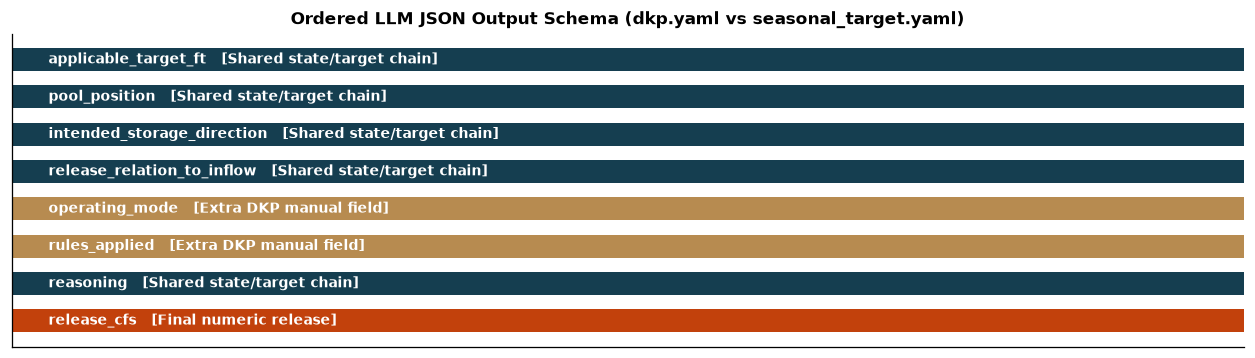

In [4]:
schemas = json.loads((fe / "study" / "response_schemas.json").read_text(encoding="utf-8"))
st_fields = list(schemas["seasonal_target"]["properties"])
dkp_fields = list(schemas["dkp"]["properties"])

fig, ax = plt.subplots(figsize=(11.0, 3.2))
all_fields = dkp_fields
y = np.arange(len(all_fields))[::-1]
colors = [C["gold"] if f not in st_fields else (C["coral"] if f == "release_cfs" else C["navy"]) for f in all_fields]
ax.barh(y, [1.0] * len(all_fields), color=colors, height=0.62)
for yi, f in zip(y, all_fields):
    tag = "Extra DKP manual field" if f not in st_fields else ("Final numeric release" if f == "release_cfs" else "Shared state/target chain")
    ax.text(0.03, yi, f"{f}   [{tag}]", va="center", color="white", fontsize=8.5, fontweight="bold")
ax.set_xlim(0, 1.0); ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Ordered LLM JSON Output Schema (dkp.yaml vs seasonal_target.yaml)")
plt.tight_layout(); plt.show()